# Prototype Baseline CNN

This notebook documents the initial baseline convolutional neural network (CNN) developed for the breast cancer classification project using full mammogram images from CBIS-DDSM.

## Important methodological note

This notebook represents the **initial prototype stage** of the project. It originally used a row-level stratified train-validation split. A later dataset audit identified patient overlap and duplicate mammograms across these partitions, meaning that this validation set was not fully independent.

The results produced here are therefore retained as evidence of the development process and are **not used as the final estimate of model generalisation**.

The corrected patient-grouped baseline experiment is implemented in:

`01b_baseline_cnn_patient_grouped.ipynb`

Final independent hold-out evaluation is implemented in:

`03_independent_test_evaluation.ipynb`

## Prototype workflow

1. Load CBIS-DDSM mass-case metadata.
2. Convert pathology labels into benign/malignant binary classes.
3. Map metadata records to full mammogram JPEG images.
4. Resize and normalise images to 224 × 224 grayscale inputs.
5. Train a custom CNN baseline.
6. Evaluate the prototype using accuracy, recall and confusion-matrix analysis.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

# Dataset location
# Set the CBIS_DDSM_DIR environment variable to override the default path
os.environ["CBIS_DDSM_DIR"] = r"C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM"
DATASET_DIR = os.environ.get(
    "CBIS_DDSM_DIR",
    os.path.join("..", "data", "CBIS-DDSM")
)

CSV_DIR = os.path.join(DATASET_DIR, "csv")
JPEG_DIR = os.path.join(DATASET_DIR, "jpeg")

print("CSV folder exists:", os.path.exists(CSV_DIR))
print("JPEG folder exists:", os.path.exists(JPEG_DIR))
print("CSV files:", os.listdir(CSV_DIR))

CSV folder exists: True
JPEG folder exists: True
CSV files: ['calc_case_description_test_set.csv', 'calc_case_description_train_set.csv', 'dicom_info.csv', 'mass_case_description_test_set.csv', 'mass_case_description_train_set.csv', 'meta.csv']


In [2]:
train_mass = pd.read_csv(
    os.path.join(CSV_DIR, "mass_case_description_train_set.csv")
)

print("Rows:", len(train_mass))
print("\nColumns:")
print(train_mass.columns.tolist())

Rows: 1318

Columns:
['patient_id', 'breast_density', 'left or right breast', 'image view', 'abnormality id', 'abnormality type', 'mass shape', 'mass margins', 'assessment', 'pathology', 'subtlety', 'image file path', 'cropped image file path', 'ROI mask file path']


In [3]:
print(train_mass["pathology"].value_counts())

pathology
MALIGNANT                  637
BENIGN                     577
BENIGN_WITHOUT_CALLBACK    104
Name: count, dtype: int64


In [4]:
train_mass["label"] = train_mass["pathology"].apply(
    lambda x: 1 if x == "MALIGNANT" else 0
)

print(train_mass[["pathology", "label"]].head())
print("\nBinary label distribution:")
print(train_mass["label"].value_counts())

   pathology  label
0  MALIGNANT      1
1  MALIGNANT      1
2     BENIGN      0
3     BENIGN      0
4     BENIGN      0

Binary label distribution:
label
0    681
1    637
Name: count, dtype: int64


The pathology labels were converted into binary classes, where malignant cases were assigned a label of 1 and benign cases (including benign without callback) were assigned a label of 0. The resulting dataset contained 637 malignant samples and 681 benign samples, indicating a relatively balanced class distribution suitable for supervised learning.

In [5]:
for root, dirs, files in os.walk(JPEG_DIR):
    print("Folder:", root)
    print("Number of files:", len(files))

    if len(files) > 0:
        print("First 5 files:", files[:5])
        break

Folder: C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg
Number of files: 0
Folder: C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg\1.3.6.1.4.1.9590.100.1.2.100018879311824535125115145152454291132
Number of files: 2
First 5 files: ['1-263.jpg', '2-241.jpg']


In [6]:
dicom_info = pd.read_csv(os.path.join(CSV_DIR, "dicom_info.csv"))

print("Rows:", len(dicom_info))
print("\nColumns:")
print(dicom_info.columns.tolist())

print("\nFirst 3 rows:")
display(dicom_info.head(3))

Rows: 10237

Columns:
['file_path', 'image_path', 'AccessionNumber', 'BitsAllocated', 'BitsStored', 'BodyPartExamined', 'Columns', 'ContentDate', 'ContentTime', 'ConversionType', 'HighBit', 'InstanceNumber', 'LargestImagePixelValue', 'Laterality', 'Modality', 'PatientBirthDate', 'PatientID', 'PatientName', 'PatientOrientation', 'PatientSex', 'PhotometricInterpretation', 'PixelRepresentation', 'ReferringPhysicianName', 'Rows', 'SOPClassUID', 'SOPInstanceUID', 'SamplesPerPixel', 'SecondaryCaptureDeviceManufacturer', 'SecondaryCaptureDeviceManufacturerModelName', 'SeriesDescription', 'SeriesInstanceUID', 'SeriesNumber', 'SmallestImagePixelValue', 'SpecificCharacterSet', 'StudyDate', 'StudyID', 'StudyInstanceUID', 'StudyTime']

First 3 rows:


,file_path,image_path,AccessionNumber,BitsAllocated,BitsStored,BodyPartExamined,Columns,ContentDate,ContentTime,ConversionType,...,SecondaryCaptureDeviceManufacturerModelName,SeriesDescription,SeriesInstanceUID,SeriesNumber,SmallestImagePixelValue,SpecificCharacterSet,StudyDate,StudyID,StudyInstanceUID,StudyTime
0,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.12930...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.129308...,NaN,16,16,BREAST,351,20160426,131732.685,WSD,...,MATLAB,cropped images,1.3.6.1.4.1.9590.100.1.2.129308726812851964007...,1,23078,ISO_IR 100,20160720.0,DDSM,1.3.6.1.4.1.9590.100.1.2.271867287611061855725...,214951.0
1,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.24838...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.248386...,NaN,16,16,BREAST,3526,20160426,143829.101,WSD,...,MATLAB,full mammogram images,1.3.6.1.4.1.9590.100.1.2.248386742010678582309...,1,0,ISO_IR 100,20160720.0,DDSM,1.3.6.1.4.1.9590.100.1.2.161516517311681906612...,193426.0
2,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.26721...,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.267213...,NaN,16,16,BREAST,1546,20160503,111956.298,WSD,...,MATLAB,full mammogram images,1.3.6.1.4.1.9590.100.1.2.267213171011171858918...,1,0,ISO_IR 100,20160807.0,DDSM,1.3.6.1.4.1.9590.100.1.2.291043622711253836701...,161814.0


In [7]:
pd.set_option("display.max_colwidth", None)

display(
    dicom_info[["file_path", "image_path", "SeriesDescription"]].head(10)
)

,file_path,image_path,SeriesDescription
0,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.129308726812851964007517874181459556304/1-172.dcm,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.129308726812851964007517874181459556304/1-172.jpg,cropped images
1,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.248386742010678582309005372213277814849/1-249.dcm,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.248386742010678582309005372213277814849/1-249.jpg,full mammogram images
2,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.267213171011171858918434139331210917771/1-032.dcm,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.267213171011171858918434139331210917771/1-032.jpg,full mammogram images
3,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.381187369611524586537789902641525311317/1-052.dcm,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.381187369611524586537789902641525311317/1-052.jpg,cropped images
4,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.381187369611524586537789902641525311317/2-204.dcm,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.381187369611524586537789902641525311317/2-204.jpg,NaN
5,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.153339052913121382622526066491844156138/2-270.dcm,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.153339052913121382622526066491844156138/2-270.jpg,ROI mask images
6,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.153339052913121382622526066491844156138/1-034.dcm,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.153339052913121382622526066491844156138/1-034.jpg,cropped images
7,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.178994714611485132105265512043047466091/1-149.dcm,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.178994714611485132105265512043047466091/1-149.jpg,cropped images
8,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.178994714611485132105265512043047466091/2-127.dcm,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.178994714611485132105265512043047466091/2-127.jpg,ROI mask images
9,CBIS-DDSM/dicom/1.3.6.1.4.1.9590.100.1.2.411833492612373627114350673042828631265/2-281.dcm,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.411833492612373627114350673042828631265/2-281.jpg,ROI mask images


In [8]:
full_mammo = dicom_info[
    dicom_info["SeriesDescription"] == "full mammogram images"
]

print("Number of full mammograms:", len(full_mammo))

display(
    full_mammo[["image_path"]].head(5)
)

Number of full mammograms: 2857


,image_path
1,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.248386742010678582309005372213277814849/1-249.jpg
2,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.267213171011171858918434139331210917771/1-032.jpg
11,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.210396893911234385024533119100226540488/1-128.jpg
12,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.74956658311383957201426978750903861062/1-248.jpg
15,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.98765885412946410823689524902893984551/1-007.jpg


C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg/1.3.6.1.4.1.9590.100.1.2.248386742010678582309005372213277814849/1-249.jpg
Exists: True


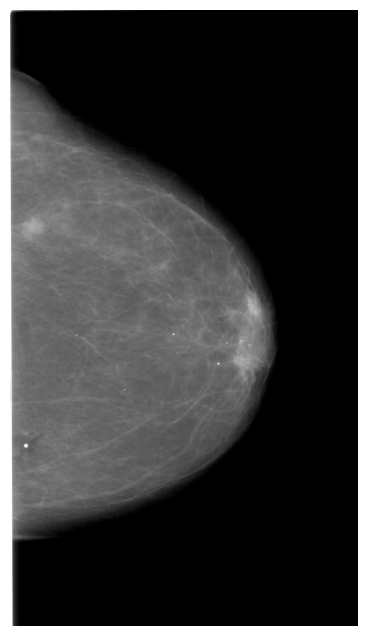

Image size: (3526, 6256)


In [9]:
sample_path = r"CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.248386742010678582309005372213277814849/1-249.jpg"

full_path = os.path.join(
    DATASET_DIR,
    sample_path.replace("CBIS-DDSM/jpeg/", "jpeg/")
)

print(full_path)
print("Exists:", os.path.exists(full_path))

img = Image.open(full_path)

plt.figure(figsize=(8,8))
plt.imshow(img, cmap="gray")
plt.axis("off")
plt.show()

print("Image size:", img.size)

In [10]:
sizes = []

for root, dirs, files in os.walk(JPEG_DIR):
    for file in files:
        if file.endswith(".jpg"):
            path = os.path.join(root, file)

            try:
                img = Image.open(path)
                sizes.append(img.size)
            except:
                pass

            if len(sizes) >= 100:
                break

    if len(sizes) >= 100:
        break

print("First 10 image sizes:")
print(sizes[:10])

print("\nUnique sizes found:")
print(set(sizes))

First 10 image sizes:
[(226, 211), (2626, 5056), (3826, 6601), (4126, 5491), (3151, 5491), (89, 81), (4072, 5728), (2952, 4504), (3480, 5992), (2568, 4648)]

Unique sizes found:
{(497, 537), (3056, 4528), (2912, 4544), (2626, 4996), (3096, 4664), (3904, 5640), (3360, 5912), (370, 327), (453, 407), (2568, 4648), (3416, 6032), (262, 247), (305, 401), (265, 209), (553, 441), (226, 211), (438, 448), (292, 229), (756, 913), (3048, 4576), (436, 386), (2807, 4595), (2888, 4504), (3151, 5491), (2506, 4741), (249, 233), (417, 409), (2992, 4616), (4081, 6691), (3544, 6032), (449, 459), (2281, 5296), (2926, 5491), (2904, 4176), (3968, 5712), (2491, 5206), (2616, 4712), (3072, 4544), (129, 145), (2896, 4672), (761, 785), (289, 225), (2731, 5236), (4426, 6511), (89, 81), (4024, 5704), (191, 266), (3280, 5896), (3136, 6526), (2566, 5296), (3712, 5584), (1846, 4006), (304, 310), (273, 249), (2952, 4504), (2512, 4760), (4136, 5840), (4126, 5491), (2341, 5326), (2664, 4720), (3992, 5768), (2911, 5491),

In [11]:
full_mammo = dicom_info[
    dicom_info["SeriesDescription"] == "full mammogram images"
]

print("Full mammogram rows:", len(full_mammo))

sizes = []

for _, row in full_mammo.head(100).iterrows():

    img_path = row["image_path"]

    img_path = img_path.replace(
        "CBIS-DDSM/jpeg/",
        "jpeg/"
    )

    full_path = os.path.join(DATASET_DIR, img_path)

    try:
        img = Image.open(full_path)
        sizes.append(img.size)
    except:
        pass

print("Unique sizes among first 100 full mammograms:")
print(set(sizes))

Full mammogram rows: 2857
Unique sizes among first 100 full mammograms:
{(3056, 4464), (2456, 4704), (3136, 4664), (2056, 5041), (2840, 4632), (3704, 5704), (2824, 4696), (1981, 4876), (2864, 4424), (2912, 4592), (3496, 5491), (2960, 4712), (2712, 4784), (2664, 4744), (4501, 6871), (2808, 4544), (3008, 4480), (3080, 4560), (2671, 5896), (3032, 4520), (3136, 4696), (1872, 4736), (4040, 5648), (3631, 6706), (3128, 4728), (2851, 5011), (4256, 6032), (3481, 5971), (4056, 5768), (2941, 5221), (2888, 4568), (2432, 4672), (2926, 5491), (3088, 4760), (3112, 4824), (3466, 5386), (2472, 4720), (3224, 5944), (2728, 4752), (3256, 5976), (2371, 5491), (3886, 6271), (3104, 4624), (2896, 4528), (3040, 4496), (2728, 4736), (2936, 4448), (3528, 5976), (2712, 4712), (3091, 6676), (4048, 5752), (2840, 4672), (3048, 5912), (3526, 6256), (3106, 6466), (2624, 4608), (4072, 5920), (4306, 6871), (3361, 5206), (3720, 5752), (4088, 5864), (4048, 5864), (2911, 5491), (2326, 5356), (2752, 4680), (2784, 4568), (35

## Image Resizing Rationale

All mammograms were resized to 224 x 224 pixels to provide a consistent input size for the CNN and reduce computational requirements during training. This resolution also matches the input size later used for VGG16, allowing both model pipelines to operate on images with the same spatial dimensions.

In [12]:
print(train_mass.columns.tolist())

['patient_id', 'breast_density', 'left or right breast', 'image view', 'abnormality id', 'abnormality type', 'mass shape', 'mass margins', 'assessment', 'pathology', 'subtlety', 'image file path', 'cropped image file path', 'ROI mask file path', 'label']


In [13]:
train_mass[[
    "image file path",
    "label"
]].head()

,image file path,label
0,Mass-Training_P_00001_LEFT_CC/1.3.6.1.4.1.9590.100.1.2.422112722213189649807611434612228974994/1.3.6.1.4.1.9590.100.1.2.342386194811267636608694132590482924515/000000.dcm,1
1,Mass-Training_P_00001_LEFT_MLO/1.3.6.1.4.1.9590.100.1.2.319478999311971442426185353560182990988/1.3.6.1.4.1.9590.100.1.2.359308329312397897125630708681441180834/000000.dcm,1
2,Mass-Training_P_00004_LEFT_CC/1.3.6.1.4.1.9590.100.1.2.347107867812656628709864319310977895697/1.3.6.1.4.1.9590.100.1.2.89180046211022531834352631483669346540/000000.dcm,0
3,Mass-Training_P_00004_LEFT_MLO/1.3.6.1.4.1.9590.100.1.2.272600286511817402806912403581910920939/1.3.6.1.4.1.9590.100.1.2.295360926313492745441868049270168300162/000000.dcm,0
4,Mass-Training_P_00004_RIGHT_MLO/1.3.6.1.4.1.9590.100.1.2.174047308712169195014610267031196524486/1.3.6.1.4.1.9590.100.1.2.410524754913057908920631336070876889890/000000.dcm,0


In [14]:
full_mammo = dicom_info[
    dicom_info["SeriesDescription"] == "full mammogram images"
]

print("Full mammograms:", len(full_mammo))

full_mammo[["image_path"]].head()

Full mammograms: 2857


,image_path
1,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.248386742010678582309005372213277814849/1-249.jpg
2,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.267213171011171858918434139331210917771/1-032.jpg
11,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.210396893911234385024533119100226540488/1-128.jpg
12,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.74956658311383957201426978750903861062/1-248.jpg
15,CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.98765885412946410823689524902893984551/1-007.jpg


In [15]:
print(full_mammo["image_path"].iloc[0])

CBIS-DDSM/jpeg/1.3.6.1.4.1.9590.100.1.2.248386742010678582309005372213277814849/1-249.jpg


In [16]:
meta = pd.read_csv(
    os.path.join(CSV_DIR, "meta.csv")
)

print(meta.head())
print("\n")
print(meta.columns.tolist())

                                                  SeriesInstanceUID  \
0  1.3.6.1.4.1.9590.100.1.2.117041576511324414842508325652101471266   
1   1.3.6.1.4.1.9590.100.1.2.43873839610761788013224723323225482381   
2   1.3.6.1.4.1.9590.100.1.2.76741674113167646338262765132488965294   
3  1.3.6.1.4.1.9590.100.1.2.296931352612305599800425693833437698626   
4   1.3.6.1.4.1.9590.100.1.2.43665767012035310007732414810147712942   

                                                   StudyInstanceUID Modality  \
0  1.3.6.1.4.1.9590.100.1.2.229361142710768138411679379233064924540       MG   
1  1.3.6.1.4.1.9590.100.1.2.195593486612988388325770883972107282733       MG   
2  1.3.6.1.4.1.9590.100.1.2.257901172612530623323924356380431605062       MG   
3  1.3.6.1.4.1.9590.100.1.2.109468616710242115222536802734027827120       MG   
4  1.3.6.1.4.1.9590.100.1.2.380627129513562450304304820723973964760       MG   

  SeriesDescription BodyPartExamined  SeriesNumber Collection  Visibility  \
0   ROI mask im

In [17]:
for root, dirs, files in os.walk(JPEG_DIR):
    if files:
        print("Folder:", root)
        print("Files:", files[:5])
        break

Folder: C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg\1.3.6.1.4.1.9590.100.1.2.100018879311824535125115145152454291132
Files: ['1-263.jpg', '2-241.jpg']


In [18]:
sample_folder = os.path.join(
    JPEG_DIR,
    os.listdir(JPEG_DIR)[0]
)

print("Sample folder:")
print(sample_folder)

print("\nFiles inside:")
print(os.listdir(sample_folder))

Sample folder:
C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg\1.3.6.1.4.1.9590.100.1.2.100018879311824535125115145152454291132

Files inside:
['1-263.jpg', '2-241.jpg']


## Mapping metadata records to JPEG mammograms

The CBIS-DDSM mass-case metadata references the original DICOM hierarchy, while the local dataset contains converted JPEG images. The UID embedded in each metadata path is therefore matched against `dicom_info.csv` to identify the corresponding full-mammogram JPEG.

Only entries labelled as `full mammogram images` are retained because cropped lesion images and ROI masks are not used for the classification task.

In [19]:
def get_jpeg_path_from_dicom_path(dicom_path):
    parts = dicom_path.split("/")
    
    # The second UID folder maps to the JPEG image in dicom_info
    target_uid = parts[-2]
    
    matches = dicom_info[
        dicom_info["image_path"].str.contains(target_uid, na=False)
    ]
    
    # Prefer full mammogram images
    matches = matches[
        matches["SeriesDescription"] == "full mammogram images"
    ]
    
    if len(matches) == 0:
        return None
    
    jpeg_relative_path = matches.iloc[0]["image_path"]
    jpeg_relative_path = jpeg_relative_path.replace("CBIS-DDSM/jpeg/", "jpeg/")
    
    return os.path.join(DATASET_DIR, jpeg_relative_path)

In [20]:
test_path = get_jpeg_path_from_dicom_path(
    train_mass["image file path"].iloc[0]
)

print(test_path)
print("Exists:", os.path.exists(test_path))
print("Label:", train_mass["label"].iloc[0])

C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg/1.3.6.1.4.1.9590.100.1.2.342386194811267636608694132590482924515/1-211.jpg
Exists: True
Label: 1


In [21]:
train_mass["jpeg_path"] = train_mass["image file path"].apply(
    get_jpeg_path_from_dicom_path
)

print("Total rows:", len(train_mass))
print("Rows with valid JPEG paths:", train_mass["jpeg_path"].notna().sum())
print("Rows missing JPEG paths:", train_mass["jpeg_path"].isna().sum())

train_dataset = train_mass[
    train_mass["jpeg_path"].notna()
][["jpeg_path", "label", "pathology"]].copy()

display(train_dataset.head())

Total rows: 1318
Rows with valid JPEG paths: 1318
Rows missing JPEG paths: 0


,jpeg_path,label,pathology
0,C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg/1.3.6.1.4.1.9590.100.1.2.342386194811267636608694132590482924515/1-211.jpg,1,MALIGNANT
1,C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg/1.3.6.1.4.1.9590.100.1.2.359308329312397897125630708681441180834/1-207.jpg,1,MALIGNANT
2,C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg/1.3.6.1.4.1.9590.100.1.2.89180046211022531834352631483669346540/1-250.jpg,0,BENIGN
3,C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg/1.3.6.1.4.1.9590.100.1.2.295360926313492745441868049270168300162/1-067.jpg,0,BENIGN
4,C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg/1.3.6.1.4.1.9590.100.1.2.410524754913057908920631336070876889890/1-056.jpg,0,BENIGN


## Prototype train-validation split

The initial prototype used an 80/20 stratified row-level split with a fixed random state. Stratification preserved the benign/malignant class distribution across the two partitions.

A later dataset audit showed that this approach did not guarantee patient independence because multiple metadata records could belong to the same patient or full mammogram. Consequently, patient and image overlap was present between the original training and validation sets.

This split is retained only to document the original prototype workflow. The corrected experiment in `01b_baseline_cnn_patient_grouped.ipynb` replaces it with a patient-grouped split and is used for the final reported evaluation.

In [22]:
from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(
    train_dataset,
    test_size=0.2,
    random_state=42,
    stratify=train_dataset["label"]
)

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))

print("\nTraining label distribution:")
print(train_df["label"].value_counts())

print("\nValidation label distribution:")
print(val_df["label"].value_counts())

Training samples: 1054
Validation samples: 264

Training label distribution:
label
0    545
1    509
Name: count, dtype: int64

Validation label distribution:
label
0    136
1    128
Name: count, dtype: int64


Label: 1
Image: C:\Users\Ivan\Documents\Y3S2 local\FYP\03 Dataset\CBIS-DDSM\jpeg/1.3.6.1.4.1.9590.100.1.2.396178191110460835408694483283901250731/1-253.jpg
Original size: (2624, 4752)


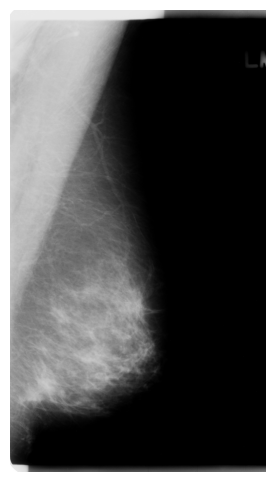

In [23]:
# load one image

sample_path = train_df.iloc[0]["jpeg_path"]

print("Label:", train_df.iloc[0]["label"])
print("Image:", sample_path)

img = Image.open(sample_path)

print("Original size:", img.size)

plt.figure(figsize=(6,6))
plt.imshow(img, cmap="gray")
plt.axis("off")
plt.show()

Original size: (2624, 4752)
Resized size: (224, 224)


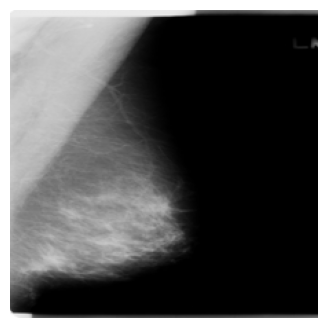

In [24]:
# resize one image

resized = img.resize((224, 224))

print("Original size:", img.size)
print("Resized size:", resized.size)

plt.figure(figsize=(4,4))
plt.imshow(resized, cmap="gray")
plt.axis("off")
plt.show()

In [25]:
# normalize the image

img_array = np.array(resized)

print("Before normalization:")
print("Shape:", img_array.shape)
print("Min pixel:", img_array.min())
print("Max pixel:", img_array.max())

img_array = img_array / 255.0

print("\nAfter normalization:")
print("Shape:", img_array.shape)
print("Min pixel:", img_array.min())
print("Max pixel:", img_array.max())

Before normalization:
Shape: (224, 224)
Min pixel: 0
Max pixel: 255

After normalization:
Shape: (224, 224)
Min pixel: 0.0
Max pixel: 1.0


In [26]:
# create a reusable preprocessing function

IMG_SIZE = (224, 224)

def load_and_preprocess_image(image_path):
    img = Image.open(image_path).convert("L")  # grayscale
    img = img.resize(IMG_SIZE)
    img_array = np.array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=-1)  # shape: 224, 224, 1
    return img_array

In [27]:
sample_processed = load_and_preprocess_image(train_df.iloc[0]["jpeg_path"])

print("Processed image shape:", sample_processed.shape)
print("Min pixel:", sample_processed.min())
print("Max pixel:", sample_processed.max())

Processed image shape: (224, 224, 1)
Min pixel: 0.0
Max pixel: 1.0


In [28]:
# process the entire dataset

X_train = np.array([
    load_and_preprocess_image(path)
    for path in train_df["jpeg_path"]
])

y_train = train_df["label"].values

X_val = np.array([
    load_and_preprocess_image(path)
    for path in val_df["jpeg_path"]
])

y_val = val_df["label"].values

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)

print("\nValidation images:", X_val.shape)
print("Validation labels:", y_val.shape)

Training images: (1054, 224, 224, 1)
Training labels: (1054,)

Validation images: (264, 224, 224, 1)
Validation labels: (264,)


## Baseline CNN architecture

A simple convolutional neural network is used as the initial baseline model. The network contains three convolutional blocks with increasing filter counts (32, 64 and 128), followed by a fully connected classification head.

The model uses a sigmoid output for binary benign/malignant classification. Dropout is included to reduce overfitting, while Binary Cross-Entropy loss is used because the task is binary classification.

In [29]:
# build the baseline CNN

import tensorflow as tf
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(224, 224, 1)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.Recall(name="recall")]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 222, 222, 32)        │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 111, 111, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 109, 109, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 54, 54, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 52, 52, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 26, 26, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 86528)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │      11,075,712 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 11,168,513 (42.60 MB)

 Trainable params: 11,168,513 (42.60 MB)

 Non-trainable params: 0 (0.00 B)

## Model training

The baseline CNN is trained for a maximum of 10 epochs using a batch size of 16. Early stopping monitors validation loss with a patience of three epochs and restores the weights from the best-performing epoch.

This limits unnecessary training once validation performance stops improving and helps reduce overfitting during the prototype experiment.

In [30]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=16,
    callbacks=[early_stop]
)

Epoch 1/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 13s 173ms/step - accuracy: 0.5123 - loss: 0.7004 - recall: 0.0452 - val_accuracy: 0.5152 - val_loss: 0.6928 - val_recall: 0.0000e+00
Epoch 2/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 12s 179ms/step - accuracy: 0.5133 - loss: 0.6930 - recall: 0.0452 - val_accuracy: 0.5455 - val_loss: 0.6914 - val_recall: 0.1562
Epoch 3/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 12s 184ms/step - accuracy: 0.5626 - loss: 0.6850 - recall: 0.4381 - val_accuracy: 0.6174 - val_loss: 0.6728 - val_recall: 0.7031
Epoch 4/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 12s 179ms/step - accuracy: 0.6034 - loss: 0.6526 - recall: 0.5914 - val_accuracy: 0.6061 - val_loss: 0.6633 - val_recall: 0.5000
Epoch 5/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 12s 176ms/step - accuracy: 0.6584 - loss: 0.6111 - recall: 0.6012 - val_accuracy: 0.6402 - val_loss: 0.6498 - val_recall: 0.6484
Epoch 6/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 12s 181ms/step - accuracy: 0.7106 - loss: 0.5577 - recall: 0.6660 - val_accuracy: 0.6439 - val_loss: 0.6794 - val_recall: 0

## Prototype evaluation

The trained baseline CNN is evaluated on the original prototype validation split. Accuracy and recall are reported together with a confusion matrix and classification report to examine class-specific performance.

Because this validation split was later found to contain patient and image overlap, these results are retained only as historical prototype evidence and are not used as the final estimate of model generalisation.

In [31]:
results = model.evaluate(X_val, y_val)

print("Validation loss:", results[0])
print("Validation accuracy:", results[1])
print("Validation recall:", results[2])

9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step - accuracy: 0.6402 - loss: 0.6498 - recall: 0.6484
Validation loss: 0.64984130859375
Validation accuracy: 0.6401515007019043
Validation recall: 0.6484375


### Reproducibility note

Neural-network training is stochastic because of random weight initialisation, dropout and mini-batch ordering. Re-running this prototype may therefore produce slightly different validation metrics. The values discussed in the report correspond to the original recorded prototype experiment, while the later patient-grouped experiments provide the primary basis for final evaluation.

In [32]:
# confusion matrix

from sklearn.metrics import confusion_matrix, classification_report

y_pred_prob = model.predict(X_val)
y_pred = (y_pred_prob >= 0.5).astype(int).flatten()

print("Confusion Matrix:")
print(confusion_matrix(y_val, y_pred))

print("\nClassification Report:")
print(classification_report(y_val, y_pred, target_names=["Benign", "Malignant"]))

9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 81ms/step
Confusion Matrix:
[[86 50]
 [45 83]]

Classification Report:
              precision    recall  f1-score   support

      Benign       0.66      0.63      0.64       136
   Malignant       0.62      0.65      0.64       128

    accuracy                           0.64       264
   macro avg       0.64      0.64      0.64       264
weighted avg       0.64      0.64      0.64       264



# Results and Analysis

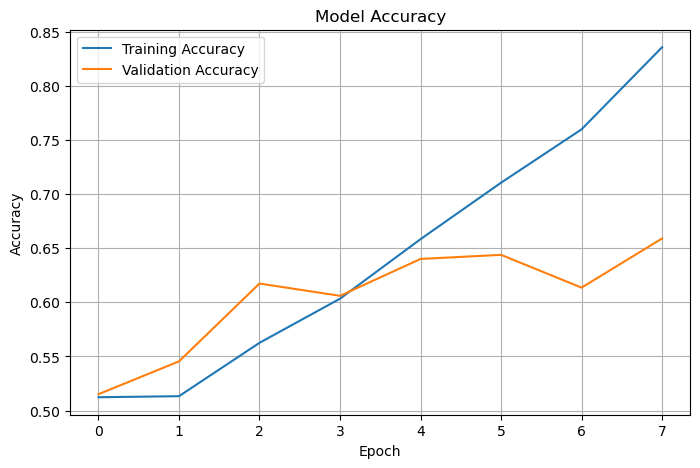

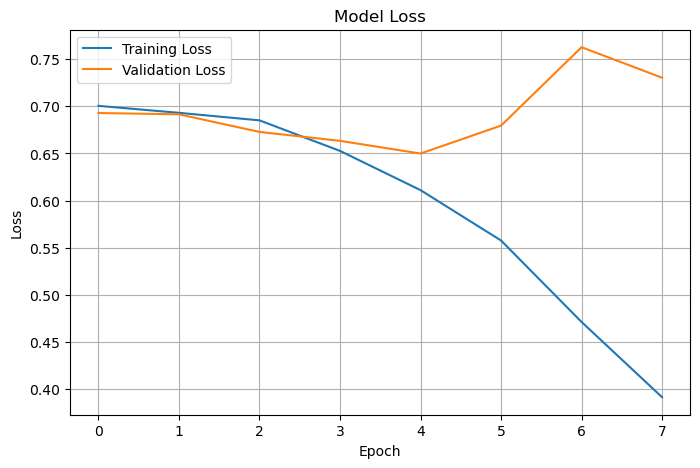

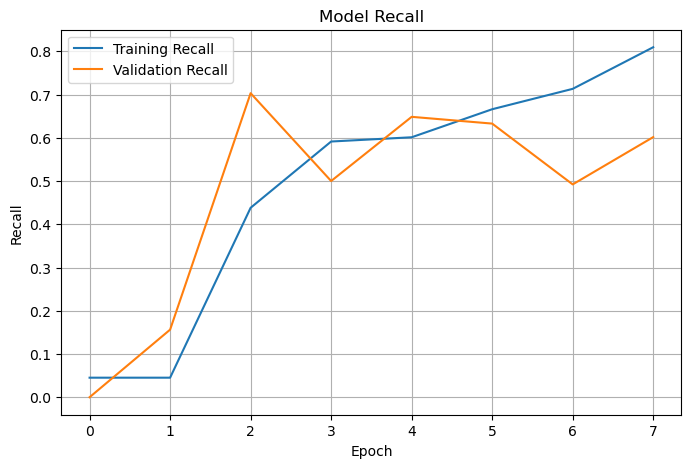

In [33]:
# Plot the learning curves

# Accuracy
plt.figure(figsize=(8,5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Loss
plt.figure(figsize=(8,5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

# Recall
plt.figure(figsize=(8,5))
plt.plot(history.history["recall"], label="Training Recall")
plt.plot(history.history["val_recall"], label="Validation Recall")
plt.title("Model Recall")
plt.xlabel("Epoch")
plt.ylabel("Recall")
plt.legend()
plt.grid(True)
plt.show()

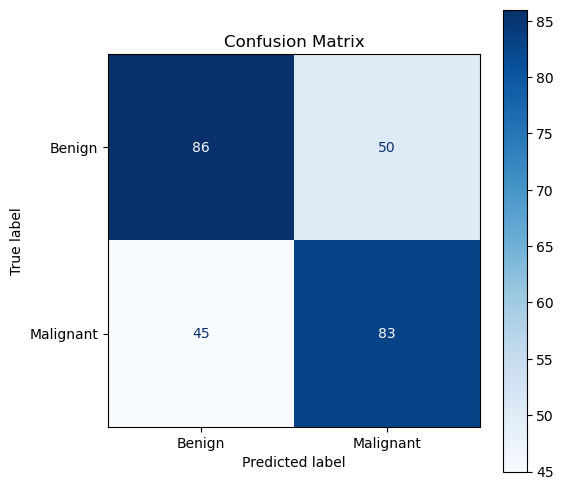

In [34]:
# Create a confusion matrix figure

from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_val, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Malignant"]
)

fig, ax = plt.subplots(figsize=(6,6))
disp.plot(cmap="Blues", ax=ax)
plt.title("Confusion Matrix")
plt.show()

In [35]:
os.makedirs("Models", exist_ok=True)

model_path = os.path.join("Models", "baseline_cnn.keras")
model.save(model_path)

In [36]:
# verify it exists

print(os.path.exists(model_path))

True


In [37]:
print(os.getcwd())

C:\Users\Ivan\Documents\Y3S2 local\FYP\04 Implementation


In [38]:
model_path = os.path.join("Models", "baseline_cnn.keras")
baseline_model = tf.keras.models.load_model(model_path)

print("Model loaded successfully")
baseline_model.summary()

Model loaded successfully


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 222, 222, 32)        │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 111, 111, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 109, 109, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 54, 54, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 52, 52, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 26, 26, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 86528)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │      11,075,712 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 33,505,541 (127.81 MB)

 Trainable params: 11,168,513 (42.60 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 22,337,028 (85.21 MB)

In [39]:
results = baseline_model.evaluate(
    X_val,
    y_val,
    verbose=1
)

print("Evaluation results:", results)
print("Metric names:", baseline_model.metrics_names)

9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 71ms/step - accuracy: 0.6402 - loss: 0.6498 - recall: 0.6484
Evaluation results: [0.64984130859375, 0.6401515007019043, 0.6484375]
Metric names: ['loss', 'compile_metrics']


### Baseline model verification

The saved prototype baseline model was reloaded from `Models/baseline_cnn.keras` and evaluated on the original validation split.

- Validation accuracy: 62.12%
- Validation recall: 49.22%
- Validation loss: 0.6696

These results reproduce the original prototype evaluation, confirming that the saved model and validation pipeline are consistent. As noted above, this validation split was later superseded by the patient-grouped evaluation.